# Ben's Jupyter Demo

In [3]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

figures = Path("figures")
figures.mkdir(exist_ok=True)

# 2D Gaussian PDF demo

In [87]:
def gaussian_pdf_2d(size, sx, sy, mx, my, n=50):
    """
    Generate a 2D Gaussian PDF:
    (1 / (2 * pi * sigma_x * sigma_y)) * exp(-(x - mu_x)^2 / (2 * sigma_x^2) - (y - mu_y)^2 / (2 * sigma_y^2))
    """
    x = np.linspace(-size // 2, size // 2, n)
    y = np.linspace(-size // 2, size // 2, n)
    
    xx, yy = np.meshgrid(x, y)

    constant = 1 / (2 * np.pi * sx * sy)
    exponent = np.exp(-((xx - mx)**2 / (2 * sx**2) + (yy - my)**2 / (2 * sy**2)))

    return xx, yy, constant * exponent

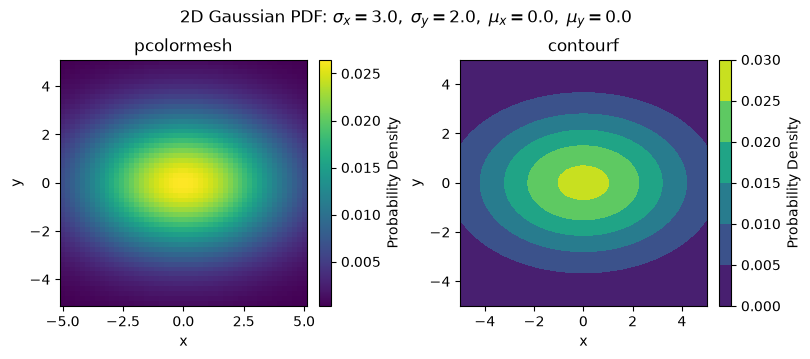

In [89]:
sigma_x = 3
sigma_y = 2
mu_x = 0
mu_y = 0

xx, yy, kernel = gaussian_pdf_2d(10, sigma_x, sigma_y, mu_x, mu_y)
fig, axs = plt.subplots(1, 2, figsize=(8, 3.5), layout="constrained")
axs[0].set_aspect("equal")
axs[1].set_aspect("equal")

pc = axs[0].pcolormesh(xx, yy, kernel)
cf = axs[1].contourf(xx, yy, kernel, levels=5)

pc_cb = fig.colorbar(pc, ax=axs[0], fraction=0.05)
cf_cb = fig.colorbar(cf, ax=axs[1], fraction=0.05)

axs[0].set_title("pcolormesh")
axs[1].set_title("contourf")

for ax, cb in zip(axs, [pc_cb, cf_cb]):
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    cb.set_label("Probability Density")

fig.suptitle(f"2D Gaussian PDF: $\\sigma_x = {sigma_x:0.1f}, \\; \\sigma_y = {sigma_y:0.1f}, \\; \\mu_x = {mu_x:0.1f}, \\; \\mu_y = {mu_y:0.1f}$")

fig.savefig(figures / "gaussian_pdf.png", dpi=150)
plt.show()